# Лабораторная работа №3
# Оптимизация гиперпараметров

## Цель работы

Научиться корректно подбирать гиперпараметры моделей машинного обучения с помощью кросс-валидации, сравнивать стратегии поиска Grid Search и Random Search, а также оценивать влияние гиперпараметров на качество модели.

## Задачи работы

1. Выбрать задачу и модель из предыдущей лабораторной работы.
2. Определить исходное качество модели (baseline).
3. Выбрать не менее трёх значимых гиперпараметров и обосновать диапазоны их значений.
4. Провести подбор гиперпараметров с использованием кросс-валидации.
5. Выполнить Grid Search и Random Search.
6. Исследовать влияние гиперпараметров на качество модели.
7. Сравнить результаты исходной и оптимизированных моделей.
8. Проанализировать устойчивость моделей и сформулировать выводы.

## 1. Выбор задачи и модели

В данной лабораторной работе используется датасет Titanic, рассмотренный в лабораторной работе №2.

Задача заключается в предсказании выживания пассажиров на основе их характеристик. Целевой переменной является `Survived`, где:
- 0 — пассажир не выжил;
- 1 — пассажир выжил.

Для оптимизации выбрана модель **Random Forest (случайный лес)**, которая представляет собой ансамбль деревьев решений.

Основной метрикой оценки качества выбрана **F1-score**, объединяющая Precision и Recall. Эта метрика позволяет оценивать качество классификации с учётом ошибок обоих типов.

В ходе работы будет исследовано влияние гиперпараметров случайного леса на его качество и способность обобщать данные.

In [4]:

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


In [5]:

# Основные настройки эксперимента
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5

# Загрузка датасета
df = pd.read_csv("Titanic-Dataset.csv")

# Просмотр первых строк
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:

print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nРаспределение целевой переменной:")
print(df["Survived"].value_counts())


Размер датасета: (891, 12)

Типы данных:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Количество пропусков:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Распределение целевой переменной:
Survived
0    549
1    342
Name: count, dtype: int64


## 2. Подготовка данных

Для обучения модели используются следующие признаки:

- `Pclass` — класс пассажирского билета;
- `Sex` — пол пассажира;
- `Age` — возраст;
- `SibSp` — количество братьев, сестёр и супругов на борту;
- `Parch` — количество родителей и детей на борту;
- `Fare` — стоимость билета;
- `Embarked` — порт посадки.

Столбцы `PassengerId`, `Name`, `Ticket` и `Cabin` исключаются из обучения.

Числовые пропуски будут заполнены медианой, категориальные — наиболее частым значением. Категориальные признаки преобразуются в числовой формат с помощью One-Hot Encoding.

Данные разделяются на обучающую (80%) и тестовую (20%) выборки с сохранением соотношения классов.

Предобработка выполняется внутри Pipeline, чтобы избежать утечки информации при кросс-валидации.

In [8]:

# Выбор признаков
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

X = df[numeric_features + categorical_features]
y = df["Survived"]

# Разделение на train и test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)


Размер обучающей выборки: (712, 7)
Размер тестовой выборки: (179, 7)


## 3. Исходная модель (Baseline)

В качестве исходной модели используется Random Forest Classifier с базовыми гиперпараметрами:

- `n_estimators = 100` — количество деревьев в лесу;
- `max_depth = None` — глубина деревьев не ограничена;
- `min_samples_leaf = 1` — минимальное количество объектов в листе;
- `random_state = 42` — обеспечивает воспроизводимость результатов.

Исходная модель служит базовым ориентиром (baseline), с которым будут сравниваться результаты оптимизации гиперпараметров.

Для оценки качества используется метрика F1-score. Качество модели определяется с помощью кросс-валидации на обучающей выборке.

In [13]:

# Предобработка признаков
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Исходная модель Random Forest
baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=1,
        random_state=RANDOM_STATE
    ))
])


## 4. Кросс-валидация

Для оценки качества модели используется метод Stratified K-Fold с количеством разбиений `k = 5`.

Обучающая выборка разделяется на пять частей. На каждой итерации четыре части используются для обучения модели, а оставшаяся — для проверки качества.

Метод StratifiedKFold сохраняет примерно одинаковое соотношение классов в каждом разбиении, что важно для задачи классификации.

**Почему выбрано 5 разбиений?**

Пять разбиений обеспечивают разумный баланс между надёжностью оценки и временем вычислений.

**Зачем нужна кросс-валидация?**

Кросс-валидация позволяет оценить способность модели обобщать данные и уменьшает зависимость результата от одного случайного разбиения.

Одного разделения train/test недостаточно для подбора гиперпараметров, поскольку результат может сильно зависеть от состава выборки.

Многократный подбор параметров на тестовых данных приводит к утечке информации и завышенной оценке качества. Поэтому тестовая выборка будет использоваться только после завершения оптимизации.

In [14]:

# Настройка кросс-валидации
cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Оценка исходной модели
baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    return_train_score=True
)

# Средние значения метрик
baseline_train_f1 = baseline_scores["train_score"].mean()
baseline_cv_f1 = baseline_scores["test_score"].mean()
baseline_cv_std = baseline_scores["test_score"].std()

print(f"Train F1: {baseline_train_f1:.4f}")
print(f"CV F1: {baseline_cv_f1:.4f}")
print(f"CV std: {baseline_cv_std:.4f}")

# Результаты отдельных разбиений
fold_results = pd.DataFrame({
    "Fold": range(1, N_FOLDS + 1),
    "Train F1": baseline_scores["train_score"],
    "CV F1": baseline_scores["test_score"]
})

display(fold_results.round(4))


Train F1: 0.9770
CV F1: 0.7403
CV std: 0.0216


,Fold,Train F1,CV F1
0,1,0.9724,0.7477
1,2,0.9814,0.7290
2,3,0.9747,0.7778
3,4,0.9745,0.7143
4,5,0.9819,0.7327


### Вывод по исходной модели

В сохранённом запуске исходная модель Random Forest показала Train F1 = 0.9770 и средний CV F1 = 0.7403. Значительный разрыв между ними указывает на возможное переобучение.

Стандартное отклонение CV F1 между пятью folds составило 0.0216 (`ddof=0`). На основании этих результатов проверим, могут ли настройки гиперпараметров повысить валидационное качество. Улучшение заранее не гарантировано.

## 5. Выбор гиперпараметров

Для Random Forest выбраны три значимых гиперпараметра. Используется **ограниченная учебная сетка**: она позволяет сравнить модели разной сложности и сохранить умеренное время расчётов (36 комбинаций × 5 folds = 180 CV-обучений), но не охватывает все возможные настройки.

**1. `n_estimators` — количество деревьев**

Диапазон: `[50, 100, 200]`. Значение 50 представляет сравнительно небольшой ансамбль, 100 соответствует baseline, а 200 позволяет проверить, даёт ли удвоение числа деревьев дополнительную пользу. Большее число деревьев обычно повышает устойчивость ансамбля, но увеличивает вычислительные затраты; само по себе оно не делает каждое дерево сложнее.

**2. `max_depth` — максимальная глубина деревьев**

Диапазон: `[3, 5, 8, None]`. Глубины 3 и 5 ограничивают сложность дерева, 8 допускает более подробные разбиения, а `None` сохраняет настройку baseline без ограничения глубины. Малые значения могут приводить к недообучению, большие — к более выраженному разрыву между Train и CV. При этом глубины 1–2 в данной сетке не проверяются, поэтому наиболее простые модели здесь не исследованы.

**3. `min_samples_leaf` — минимальное число объектов в листе**

Диапазон: `[1, 2, 4]`. Значение 1 соответствует baseline; значения 2 и 4 последовательно ограничивают создание листьев с малым числом объектов. Увеличение параметра обычно уменьшает сложность дерева и Train F1, но влияние на CV F1 необходимо проверять экспериментально. Очень крупные листья (например, 20–50 объектов) здесь не рассматриваются.

Таким образом, диапазоны выбраны как небольшой, вычислительно доступный набор для первоначального сравнения. На основании этой сетки нельзя уверенно определить все границы недообучения и переобучения.

In [16]:

# Пространство гиперпараметров для Grid Search
param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 2, 4]
}

# Количество комбинаций
n_combinations = np.prod(
    [len(values) for values in param_grid.values()]
)

print("Количество комбинаций:", n_combinations)
print("Количество обучений с 5 folds:", n_combinations * N_FOLDS)


Количество комбинаций: 36
Количество обучений с 5 folds: 180


## 6. Оптимизация гиперпараметров с помощью Grid Search

Grid Search — метод поиска оптимальных гиперпараметров, который последовательно проверяет все комбинации значений из заданной сетки.

В данной работе рассматриваются 3 гиперпараметра Random Forest:

- `n_estimators`: 50, 100, 200;
- `max_depth`: 3, 5, 8, None;
- `min_samples_leaf`: 1, 2, 4.

Общее количество комбинаций составляет 36.

Для каждой комбинации используется пятикратная кросс-валидация, поэтому выполняется 180 обучений моделей без учёта финального переобучения лучшей модели.

Основной метрикой оптимизации является F1-score. Лучшей считается комбинация гиперпараметров, обеспечивающая максимальное среднее значение F1-score на кросс-валидации.

In [18]:

# Создание Grid Search
grid_search = GridSearchCV(
    estimator=baseline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# Измерение времени выполнения
start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start_time

# Результаты поиска
print("Лучшие гиперпараметры:")
print(grid_search.best_params_)

print(f"\nЛучший CV F1: {grid_search.best_score_:.4f}")
print(f"Время выполнения: {grid_time:.2f} сек.")
print(f"Проверено комбинаций: {len(grid_search.cv_results_['params'])}")


Лучшие гиперпараметры:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}

Лучший CV F1: 0.7478
Время выполнения: 2.21 сек.
Проверено комбинаций: 36


In [20]:

# Таблица результатов Grid Search
grid_results = pd.DataFrame(grid_search.cv_results_)

# Выбираем нужные столбцы
grid_table = grid_results[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

# Сортировка по качеству
grid_table = grid_table.sort_values("rank_test_score")

# Вывод 10 лучших комбинаций
display(grid_table.head(10).round(4))


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
31,100,None,2,0.8830,0.7478,0.0326,1
2,200,3,1,0.7563,0.7462,0.0532,2
5,200,3,2,0.7547,0.7432,0.0502,3
0,50,3,1,0.7631,0.7429,0.0446,4
32,200,None,2,0.8856,0.7420,0.0240,5
19,100,8,1,0.9008,0.7404,0.0333,6
28,100,None,1,0.9770,0.7403,0.0216,7
3,50,3,2,0.7631,0.7398,0.0399,8
18,50,8,1,0.8962,0.7389,0.0431,9
9,50,5,1,0.7980,0.7381,0.0355,10


### Вывод по Grid Search

Метод Grid Search проверил 36 комбинаций гиперпараметров с пятикратной кросс-валидацией. Лучшие настройки в сохранённом запуске: `n_estimators=100`, `max_depth=None`, `min_samples_leaf=2`. Средний CV F1 составил **0.7478** против **0.7403** у baseline; время поиска — **2.21 с**.

Прирост CV F1 равен **0.0075**, что невелико на фоне разброса значений между folds (CV std = 0.0326 у выбранной модели). Значение Train F1 уменьшилось с 0.9770 до 0.8830, поэтому разрыв между Train и CV сократился, но само по себе это **не доказывает улучшения обобщения**: часть сокращения вызвана снижением Train F1.

Grid Search нашёл комбинацию с немного более высоким средним CV F1 на использованных разбиениях. Утверждать значимое преимущество по качеству на новых данных на этом этапе нельзя.

## 7. Оптимизация гиперпараметров с помощью Random Search

Random Search случайно выбирает заданное число комбинаций гиперпараметров вместо полного перебора заранее заданной сетки.

Для сопоставимости вычислительного бюджета используется **36 комбинаций** и та же пятикратная кросс-валидация, что и для Grid Search.

Диапазоны поиска:

- `n_estimators` — от 50 до 200 с шагом 10: дополнительные размеры ансамбля при умеренных вычислительных затратах;
- `max_depth` — 3, 4, 5, 6, 7, 8, 10, `None`: более подробное исследование глубины по сравнению с Grid Search;
- `min_samples_leaf` — от 1 до 5: дополнительные значения минимального размера листа.

Пространство поиска шире, но всё ещё ограничено небольшой учебной задачей. В данном коде случайные комбинации выбираются **из списков значений**; это корректное применение `RandomizedSearchCV`. При больших диапазонах можно вместо списков использовать распределения.

Random Search может быть предпочтителен при большом пространстве поиска и фиксированном вычислительном бюджете, однако его результат зависит от случайного выбора комбинаций.

In [22]:

# Пространство поиска Random Search
param_random = {
    "model__n_estimators": list(range(50, 201, 10)),
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10, None],
    "model__min_samples_leaf": [1, 2, 3, 4, 5]
}

# Создание Random Search
random_search = RandomizedSearchCV(
    estimator=baseline,
    param_distributions=param_random,
    n_iter=36,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    return_train_score=True,
    refit=True
)

# Измерение времени выполнения
start_time = time.perf_counter()

random_search.fit(X_train, y_train)

random_time = time.perf_counter() - start_time

# Результаты поиска
print("Лучшие гиперпараметры:")
print(random_search.best_params_)

print(f"\nЛучший CV F1: {random_search.best_score_:.4f}")
print(f"Время выполнения: {random_time:.2f} сек.")
print(f"Проверено комбинаций: {len(random_search.cv_results_['params'])}")


Лучшие гиперпараметры:
{'model__n_estimators': 120, 'model__min_samples_leaf': 2, 'model__max_depth': 10}

Лучший CV F1: 0.7473
Время выполнения: 2.32 сек.
Проверено комбинаций: 36


In [24]:

# Таблица результатов Random Search
random_results = pd.DataFrame(random_search.cv_results_)

random_table = random_results[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

# Сортировка по качеству
random_table = random_table.sort_values("rank_test_score")

# Вывод 10 лучших комбинаций
display(random_table.head(10).round(4))


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
29,120,10,2,0.8750,0.7473,0.0248,1
30,80,10,3,0.8607,0.7444,0.0315,2
23,110,None,3,0.8578,0.7440,0.0304,3
8,200,3,2,0.7547,0.7432,0.0502,4
3,100,None,3,0.8570,0.7432,0.0347,5
16,180,10,3,0.8567,0.7430,0.0359,6
13,160,10,3,0.8557,0.7430,0.0359,6
6,190,4,5,0.7725,0.7425,0.0289,8
22,160,4,5,0.7716,0.7425,0.0289,8
12,150,3,1,0.7604,0.7408,0.0445,10


### Вывод по Random Search

Random Search проверил 36 комбинаций гиперпараметров с пятикратной кросс-валидацией. В сохранённом запуске выбраны `n_estimators=120`, `max_depth=10`, `min_samples_leaf=2`. Средний CV F1 составил **0.7473** против **0.7403** у baseline; время поиска — **2.32 с**.

Разница с baseline по CV F1 составляет **0.0070** — небольшой прирост по сравнению с разбросом результатов по folds (CV std = 0.0248). Train F1 снизился с 0.9770 до 0.8750. Это уменьшило разрыв Train–CV, но не позволяет уверенно утверждать, что модель лучше обобщает новые данные.

Таким образом, Random Search нашёл близкую по качеству к Grid Search комбинацию, но убедительного преимущества над baseline по одному CV-эксперименту не установлено.

## 8. Сравнение Grid Search и Random Search

Для сравнения эффективности методов оптимизации гиперпараметров используются следующие показатели:

- среднее значение F1-score на кросс-валидации;
- стандартное отклонение F1-score;
- количество проверенных комбинаций;
- время выполнения поиска.

Оба метода используют одинаковый вычислительный бюджет — 36 комбинаций и пятикратную кросс-валидацию.

In [26]:

# Сравнение результатов оптимизации
comparison = pd.DataFrame({
    "Метод": ["Baseline", "Grid Search", "Random Search"],
    "Train F1": [
        baseline_train_f1,
        grid_search.cv_results_["mean_train_score"][grid_search.best_index_],
        random_search.cv_results_["mean_train_score"][random_search.best_index_]
    ],
    "CV F1": [
        baseline_cv_f1,
        grid_search.best_score_,
        random_search.best_score_
    ],
    "CV std": [
        baseline_cv_std,
        grid_search.cv_results_["std_test_score"][grid_search.best_index_],
        random_search.cv_results_["std_test_score"][random_search.best_index_]
    ],
    "Комбинации": [1, 36, 36],
    "Время поиска (сек.)": [np.nan, grid_time, random_time]
})

display(comparison.round(4))


,Метод,Train F1,CV F1,CV std,Комбинации,Время поиска (сек.)
0,Baseline,0.977,0.7403,0.0216,1,NaN
1,Grid Search,0.883,0.7478,0.0326,36,2.2112
2,Random Search,0.875,0.7473,0.0248,36,2.3230


### Вывод по сравнению методов

В сохранённом запуске Grid Search получил CV F1 = **0.7478**, Random Search — **0.7473** при одинаковом бюджете в 36 комбинаций. Разница всего **0.0005**, поэтому **содержательного преимущества одного метода по качеству здесь не выявлено**.

Время выполнения составило **2.21 с** для Grid Search и **2.32 с** для Random Search. При столь небольшом времени поиска разница несущественна и может зависеть от накладных расходов и нагрузки компьютера.

CV std у выбранных моделей составляет **0.0326** и **0.0248** соответственно (`ddof=0`). Эти значения описывают разброс на пяти folds; их небольшое различие **не доказывает**, что один метод устойчивее другого.

Grid Search удобен для полного перебора небольшой сетки. Random Search полезен, когда пространство параметров больше и число проверок ограничено. По результатам данного эксперимента методы показали практически одинаковый уровень CV F1.

## 9. Анализ влияния гиперпараметров на качество модели

Для анализа используются уже полученные результаты Grid Search. На каждом графике изменяется **один гиперпараметр**, а два других фиксируются. Сравниваются средние Train F1 и CV F1.

Исследуются `n_estimators`, `max_depth` и `min_samples_leaf`. Анализ показывает, как изменяются качество и разрыв Train–CV в пределах **выбранной ограниченной сетки**. Области недообучения, разумной сложности и переобучения обсуждаются как возможные закономерности, а не как строго доказанные границы.

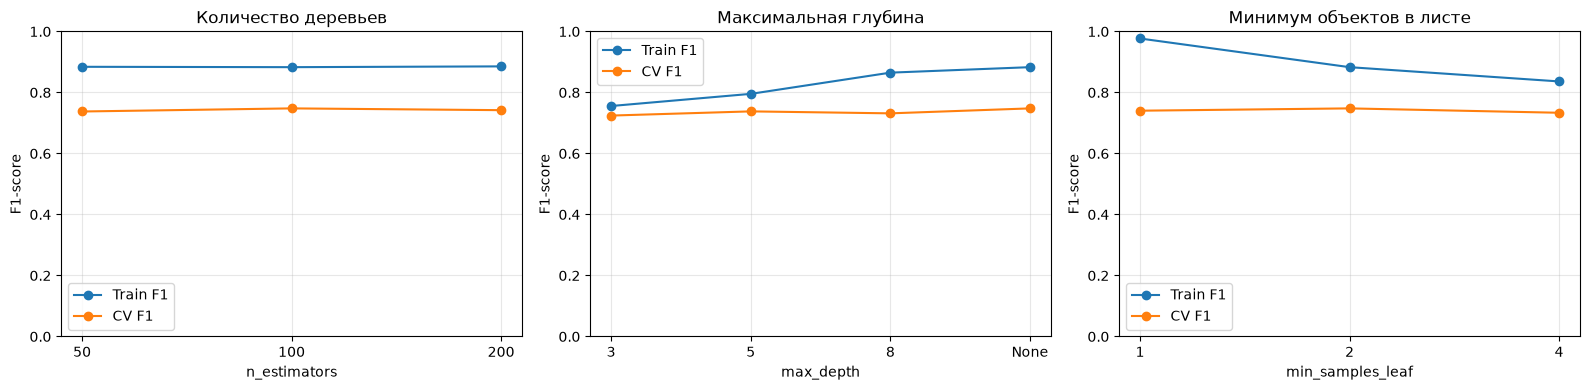

In [29]:

# Результаты Grid Search
results = pd.DataFrame(grid_search.cv_results_)

# 1. Влияние n_estimators
n_data = results[
    (results["param_model__max_depth"].isna()) &
    (results["param_model__min_samples_leaf"] == 2)
].sort_values("param_model__n_estimators")

# 2. Влияние max_depth
depth_data = results[
    (results["param_model__n_estimators"] == 100) &
    (results["param_model__min_samples_leaf"] == 2)
].copy()

depth_data["depth_order"] = depth_data[
    "param_model__max_depth"
].apply(lambda x: 999 if pd.isna(x) else int(x))

depth_data = depth_data.sort_values("depth_order")

# 3. Влияние min_samples_leaf
leaf_data = results[
    (results["param_model__n_estimators"] == 100) &
    (results["param_model__max_depth"].isna())
].sort_values("param_model__min_samples_leaf")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

datasets = [
    (
        n_data,
        "param_model__n_estimators",
        "Количество деревьев",
        "n_estimators"
    ),
    (
        depth_data,
        "param_model__max_depth",
        "Максимальная глубина",
        "max_depth"
    ),
    (
        leaf_data,
        "param_model__min_samples_leaf",
        "Минимум объектов в листе",
        "min_samples_leaf"
    )
]

for ax, (data, column, title, xlabel) in zip(axes, datasets):
    x = range(len(data))

    ax.plot(
        x, data["mean_train_score"],
        marker="o", label="Train F1"
    )
    ax.plot(
        x, data["mean_test_score"],
        marker="o", label="CV F1"
    )

    ax.set_xticks(list(x))
    ax.set_xticklabels(data[column].fillna("None").astype(str))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("F1-score")
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Вывод по влиянию гиперпараметров

**1. Количество деревьев (`n_estimators`).** При переходе от 50 к 100 и 200 деревьям показатели Train F1 и CV F1 меняются слабо. На этой сетке увеличение числа деревьев заметного выигрыша не даёт; само число деревьев не является прямым ограничением глубины или сложности отдельных деревьев.

**2. Максимальная глубина (`max_depth`).** При увеличении глубины Train F1 возрастает, а CV F1 остаётся примерно на одном уровне. Разрыв Train–CV увеличивается, что указывает на **риск переобучения** у более сложных деревьев. При глубине 3 разрыв меньше, но одного этого недостаточно, чтобы объявить такую модель недообученной: на исследованной сетке её CV F1 близок к результатам других глубин. Слишком малые глубины (1–2) не исследовались.

**3. Минимальное количество объектов в листе (`min_samples_leaf`).** При увеличении параметра Train F1 снижается, поскольку разбиения деревьев становятся более ограниченными. При фиксированных настройках остальных параметров наибольший средний CV F1 в построенном графике наблюдается при `min_samples_leaf=2`, однако различия невелики относительно разброса по folds. Делать вывод об однозначно оптимальном размере листа только по графику нельзя.

**Общий вывод.** Графики позволяют увидеть изменение сложности модели и разрыва Train–CV, но **не демонстрируют убедительно все три области** (недообучение, разумная сложность и переобучение). Для более точного выделения границ потребовался бы более широкий диапазон значений. По исходному Grid Search лучшими по среднему CV F1 оказались 100 деревьев, глубина `None` и размер листа 2.

## 10. Финальная оценка моделей

После подбора параметров проводится единственная финальная проверка на отложенной тестовой выборке. Сравниваются baseline, лучшие модели Grid Search и Random Search.

Все гиперпараметры выбирались **только на train с кросс-валидацией**. В сохранённом запуске Grid Search имеет чуть больший средний CV F1 (0.7478 против 0.7473 у Random Search), поэтому в рамках этого запуска он выбран в качестве итоговой настроенной модели **до просмотра test**. При этом различие CV между двумя поисками слишком мало, чтобы трактовать его как надёжное преимущество.

Тестовая выборка служит независимой финальной оценкой и не используется для повторного подбора гиперпараметров.

In [31]:

# Обучение исходной модели
baseline.fit(X_train, y_train)

# Лучшие модели после оптимизации
grid_model = grid_search.best_estimator_
random_model = random_search.best_estimator_

# Финальная оценка на test
baseline_test_f1 = f1_score(
    y_test, baseline.predict(X_test)
)

grid_test_f1 = f1_score(
    y_test, grid_model.predict(X_test)
)

random_test_f1 = f1_score(
    y_test, random_model.predict(X_test)
)

# Сравнение CV и Test
final_results = pd.DataFrame({
    "Модель": ["Baseline", "Grid Search", "Random Search"],
    "CV F1": [
        baseline_cv_f1,
        grid_search.best_score_,
        random_search.best_score_
    ],
    "Test F1": [
        baseline_test_f1,
        grid_test_f1,
        random_test_f1
    ]
})

display(final_results.round(4))

print(
    f"Улучшение Grid Search относительно baseline: "
    f"{grid_test_f1 - baseline_test_f1:+.4f}"
)

print(
    f"Улучшение Random Search относительно baseline: "
    f"{random_test_f1 - baseline_test_f1:+.4f}"
)


,Модель,CV F1,Test F1
0,Baseline,0.7403,0.7442
1,Grid Search,0.7478,0.7258
2,Random Search,0.7473,0.7154


Улучшение Grid Search относительно baseline: -0.0184
Улучшение Random Search относительно baseline: -0.0287


## 11. Анализ устойчивости моделей

Кроме среднего CV F1 рассматриваются значения отдельных folds и их разброс. Для согласованности со `sklearn.cv_results_` во всём ноутбуке используется **стандартное отклонение с `ddof=0`**.

При наличии только пяти folds значения стандартного отклонения являются описательной характеристикой этого разбиения. Малые различия std не позволяют уверенно установить, какая модель устойчивее в целом. Две модели с близким средним F1 могут иметь разный разброс по folds из-за состава валидационных подвыборок.

In [33]:

# F1-score исходной модели по folds
baseline_folds = baseline_scores["test_score"]

# F1-score лучшей модели Grid Search
grid_folds = [
    grid_search.cv_results_[f"split{i}_test_score"][
        grid_search.best_index_
    ]
    for i in range(N_FOLDS)
]

# F1-score лучшей модели Random Search
random_folds = [
    random_search.cv_results_[f"split{i}_test_score"][
        random_search.best_index_
    ]
    for i in range(N_FOLDS)
]

# Таблица результатов
stability = pd.DataFrame({
    "Fold": range(1, N_FOLDS + 1),
    "Baseline": baseline_folds,
    "Grid Search": grid_folds,
    "Random Search": random_folds
})

display(stability.round(4))

# Среднее и стандартное отклонение
print("\nСреднее F1 и стандартное отклонение:")
fold_metric_scores = stability.drop(columns="Fold")
summary_stability = pd.DataFrame({
    "mean": fold_metric_scores.mean(),
    "std (ddof=0)": fold_metric_scores.std(ddof=0)
}).T

display(summary_stability.round(4))


,Fold,Baseline,Grid Search,Random Search
0,1,0.7477,0.7619,0.7619
1,2,0.7290,0.7103,0.7103
2,3,0.7778,0.8039,0.7843
3,4,0.7143,0.7358,0.7379
4,5,0.7327,0.7273,0.7423



Среднее F1 и стандартное отклонение:


,Baseline,Grid Search,Random Search
mean,0.7403,0.7478,0.7473
std (ddof=0),0.0216,0.0326,0.0248


### Вывод по финальной оценке моделей

Средний CV F1 исходной модели составил **0.7403**, Grid Search — **0.7478**, Random Search — **0.7473**. Улучшение по CV небольшое: +0.0075 и +0.0070 соответственно.

На test значения F1 оказались иными: **0.7442** у baseline, **0.7258** у Grid Search и **0.7154** у Random Search. Таким образом, небольшой прирост CV F1 **не подтвердился на тестовой выборке**.

Тестовая выборка содержит всего **179 пассажиров**, поэтому несколько других правильных или ошибочных предсказаний могут заметно изменить F1. Кроме того, выбор максимального CV F1 среди 36 комбинаций может приводить к некоторому оптимизму в оценке качества выбранной комбинации. Наблюдаемые расхождения могут быть связаны с вариативностью оценок на ограниченной выборке; их недостаточно для строгого вывода о превосходстве baseline или настроенных моделей в генеральной совокупности.

При настройке деревья стали меньше подгоняться под train по значению F1 (сократился разрыв Train–CV), **но это не равнозначно доказанному улучшению качества на новых данных**. Параметры не менялись по итогам просмотра test, чтобы не допустить утечки информации.

### Вывод по анализу устойчивости

При пятикратной кросс-валидации средние F1 составили **0.7403** (baseline), **0.7478** (Grid Search) и **0.7473** (Random Search).

Стандартные отклонения с единым способом расчёта **`ddof=0`** равны **0.0216**, **0.0326** и **0.0248** соответственно. В этом конкретном разбиении baseline имеет наименьший наблюдаемый разброс, а Grid Search — наибольший.

Однако пять folds — небольшое число наблюдений для сравнения устойчивости. Поэтому эти результаты следует интерпретировать как **описательный анализ**, а не как доказательство стабильного превосходства одной модели. При близком среднем качестве важны и значения отдельных folds, поскольку они могут различаться из-за состава подвыборок.

## 12. Общий вывод

В лабораторной работе исследована оптимизация трёх гиперпараметров Random Forest (`n_estimators`, `max_depth`, `min_samples_leaf`) для классификации пассажиров Titanic.

Для подбора применялась пятикратная стратифицированная кросс-валидация. Grid Search и Random Search проверили по 36 комбинаций. В сохранённом запуске оба метода дали близкие значения CV F1: **0.7478** и **0.7473** против **0.7403** у baseline. Различия невелики по сравнению с разбросом результатов между folds; уверенного преимущества одного метода не установлено.

Исследование графиков показало, что большая глубина деревьев повышает Train F1, но не обеспечивает сопоставимого роста CV F1. Увеличение `min_samples_leaf` ограничивает сложность дерева. В рамках выбранной небольшой сетки нельзя однозначно выделить все области недообучения и переобучения.

После настройки уменьшился разрыв Train–CV, однако это произошло в том числе за счёт снижения Train F1. Финальная проверка на test **не подтвердила улучшение**: Test F1 равен **0.7442** для baseline, **0.7258** для Grid Search и **0.7154** для Random Search. На небольшой тестовой выборке оценки могут заметно колебаться, а выбор лучшего CV результата среди многих комбинаций может давать оптимистичное значение CV.

Разброс оценок по folds проанализирован с единым способом расчёта (`ddof=0`). По пяти folds различий недостаточно для надёжного ранжирования моделей по устойчивости. Все гиперпараметры выбирались без использования тестовой выборки.

**Цель работы достигнута:** проведены Grid Search и Random Search, исследовано влияние гиперпараметров и показано, почему небольшое улучшение по CV нельзя автоматически считать улучшением на новых данных.